# Topology optimization of a waveguide bend: a 90° turn in a 3 µm square

**Question.** Two waveguides 0.55 µm wide, core index 2.25 in a cladding of index
1.444, meet at a right angle. In the 3 µm × 3 µm square where they meet, each point
may be core or cladding. Which pattern carries the most power at 1.55 µm from the
fundamental mode of one guide into the fundamental mode of the other?

We let gradients find it. The design is a pixel image of the square, and the chain
from pixels to the objective is differentiable end to end:

pixels ρ → **Helmholtz filter** (length scale) → **projection** (towards core /
cladding) → **layer grid** to the mesh elements → **material field** ε_r →
`gfem.solve` → S21.

The optimizer is not part of gfem: here it is [optax](https://optax.readthedocs.io)'s
Adam, as in the [topology tutorial](topology.ipynb). The problem and its parameters
follow the BEAMZ example
["Topology Optimized 90° Bend"](https://www.beamz.tech/examples/ceviche_bend)
(Q. Wach, 2025), an FDTD design; the code and figures here are gfem's own.

**Assumptions.**

- A top view in effective indices: 2.25 and 1.444 stand for the vertical stack, as
  in the BEAMZ example. gfem poses it as a slab model, one element (0.1 µm) thick
  between PEC plates, so the electric field is along z, uniform through the
  thickness, and the problem is the 2D TM one.
- Second-order absorbing faces close the cladding 1 µm from the design square,
  instead of a PML.
- Wave ports on the two guide ends, each a 2.2 µm window with conducting edges,
  launch and measure the fundamental mode.
- Lossless media.
- The mesh (0.1 µm cells, second-order Nédélec elements) resolves the guided
  wavelength (0.75 µm) well enough for a design study; check a final design on a
  finer mesh.

**Conventions.** SI units at the API (the mesh file is in µm), time dependence
e^{+iωt}, S-parameters as power waves normalized to 1 W of mode power at each wave
port, so |S21|² is the fraction of the incident power carried out of port 2 in its
fundamental mode. See `gfem.conventions`.

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from scipy.constants import c
from scipy.optimize import brentq

import gfem
from gfem import design

um = 1e-6
WAVELENGTH = 1.55 * um
F0 = c / WAVELENGTH  # 193.4 THz

## The bend

The mesh is a 5 µm × 5 µm × 0.1 µm box centred on the bend: the BEAMZ domain
without its PML. Its volumes are `"design"` (|x|, |y| < 1.5 µm), `"core"` (the input
guide along x < -1.5 µm and the output guide along y < -1.5 µm, both centred and
0.55 µm wide) and `"cladding"`, the rest. Its surfaces are `"plates"` (z = 0 and
z = 0.1 µm), the port faces `"port1"` (x = -2.5 µm, |y| < 1.1 µm) and `"port2"`
(y = -2.5 µm, |x| < 1.1 µm), and `"outer"`, every other side face. The cells are
0.1 µm, with node lines on the guide edges and the design square's sides. It was
written by `tools/make_tutorial_meshes.py`.

The design volume starts as cladding; the optimization replaces its material. Each
wave port solves a port mode problem on its face, whose edges on `"outer"` are
conducting (`pec_edges`). The guide's fundamental mode, even with E along z, has a
closed form: tan(κw/2) = γ/κ with κ = k₀√(n_core² - n_eff²) and
γ = k₀√(n_eff² - n_cladding²). The port mode should give the same n_eff.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/bend.msh"), length_unit="um")
N_CORE, N_CLADDING, WIDTH = 2.25, 1.444, 0.55 * um
CLADDING = gfem.Material(eps_r=N_CLADDING**2, name="cladding")
CORE = gfem.Material(eps_r=N_CORE**2, name="core")

bend = gfem.Model(
    mesh,
    materials={"cladding": CLADDING, "core": CORE, "design": CLADDING},
    boundaries=[gfem.PEC("plates"), gfem.Absorbing("outer", order=2)],
    ports=[
        gfem.WavePort("p1", "port1", pec_edges=("outer",)),
        gfem.WavePort("p2", "port2", pec_edges=("outer",)),
    ],
)


def slab_index(n_core, n_cladding, width, wavelength):
    # Even mode of a symmetric slab: tan(kappa w / 2) = gamma / kappa, on the
    # fundamental branch kappa w / 2 < pi / 2.
    k0 = 2 * np.pi / wavelength

    def dispersion(n):
        kappa = k0 * np.sqrt(n_core**2 - n**2)
        gamma = k0 * np.sqrt(n**2 - n_cladding**2)
        return np.tan(kappa * width / 2) - gamma / kappa

    lowest = max(np.sqrt(n_core**2 - (wavelength / (2 * width)) ** 2), n_cladding)
    return brentq(dispersion, lowest + 1e-9, n_core - 1e-9)


mode = gfem.solve(bend, gfem.PortMode("p1", F0))
print(
    f"n_eff (p1) = {float(np.real(mode.n_eff[0])):.6f}, analytic slab mode = "
    f"{slab_index(N_CORE, N_CLADDING, WIDTH, WAVELENGTH):.6f}"
)
bend

n_eff (p1) = 2.057538, analytic slab mode = 2.057557


Model(Mesh(5618 nodes, 16224 tetrahedra, volumes=['cladding', 'core', 'design'], surfaces=['outer', 'plates', 'port1', 'port2'], length_unit='um')
  materials:
    cladding: Material(eps_r=2.085136, name='cladding')
    core: Material(eps_r=5.0625, name='core')
    design: Material(eps_r=2.085136, name='cladding')
  boundaries:
    PEC(surface='plates')
    Absorbing(surface='outer', order=2)
  ports:
    WavePort(name='p1', surface='port1', mode=1, offset=0.0, voltage_path=None, pec_edges=('outer',))
    WavePort(name='p2', surface='port2', mode=1, offset=0.0, voltage_path=None, pec_edges=('outer',)))

The design square takes its permittivity from a **layer grid**: 60 × 60 pixels of
0.05 µm over the volume's footprint (more on it in the next section). A pixel value
of 0 is cladding, 1 is core, and the material field interpolates ε_r linearly in
between, as BEAMZ does.

Below, the layout as the solver sees it: white is core, black is cladding, and the
design square is at 0.5, where the optimization starts. The port faces are read from
the mesh. Every other side face absorbs, and the plates are PEC.

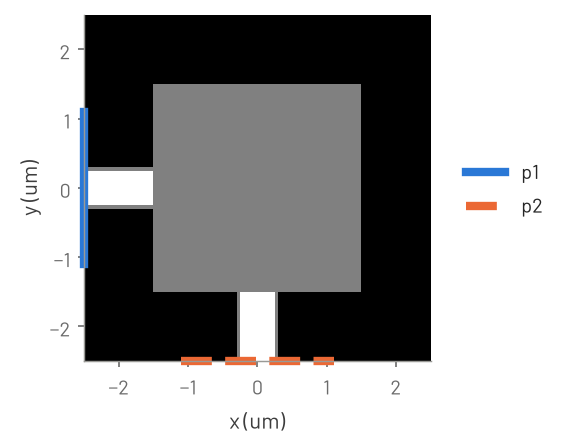

In [3]:
grid = design.LayerGrid(mesh, "design", pitch=0.05 * um)
HALF = 2.5 * um  # the box's half-width


def area_fraction(inside, x, y, pitch, samples=8):
    # Per pixel centred at (x[j], y[i]): the fraction of its area where inside(x, y).
    offsets = ((np.arange(samples) + 0.5) / samples - 0.5) * pitch
    xs = x[None, :, None, None] + offsets[None, None, None, :]
    ys = y[:, None, None, None] + offsets[None, None, :, None]
    return inside(xs, ys).mean(axis=(2, 3))


def in_arms(x, y):
    # The fixed guides: the input along x < -1.5 um, the output along y < -1.5 um.
    guide = WIDTH / 2
    return ((x < -1.5 * um) & (np.abs(y) <= guide)) | (
        (y < -1.5 * um) & (np.abs(x) <= guide)
    )


centres = -HALF + (np.arange(round(2 * HALF / grid.pitch)) + 0.5) * grid.pitch
corner_pixel = round((grid.origin[0] + HALF) / grid.pitch)  # same in x and y
inside_design = np.s_[
    corner_pixel : corner_pixel + grid.shape[0],
    corner_pixel : corner_pixel + grid.shape[1],
]
EXTENT = np.array([-HALF, HALF, -HALF, HALF]) / um


def window(density):
    # The whole 5 um x 5 um box as a pixel image: the guides around a design density.
    image = area_fraction(in_arms, centres, centres, grid.pitch)
    image[inside_design] = np.asarray(density)
    return image


start = np.full(grid.shape, 0.5)
nodes = np.asarray(mesh.nodes) / um
fig, ax = plt.subplots(figsize=(6, 3))
ax.imshow(window(start), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1)
for colour, port, face in (("C0", "p1", "port1"), ("C1", "p2", "port2")):
    xy = nodes[mesh.triangles[mesh.elements(face)]].reshape(-1, 3)[:, :2]
    lo, hi = xy.min(axis=0), xy.max(axis=0)
    ax.plot(
        [lo[0], hi[0]], [lo[1], hi[1]], color=colour, lw=4, clip_on=False, label=port
    )
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.legend(loc="center left", bbox_to_anchor=(1.05, 0.5));

Two hand-drawn bends set the scale before any optimization. The **arc design** is a
quarter ring 0.55 µm wide, of radius 1.5 µm about the corner (-1.5, -1.5) µm, that
joins the two guides; the **corner design** extends both guides until they meet in a
sharp L. Their pixels hold the area fraction of core (8 × 8 samples per pixel).

One driven problem at 1.55 µm with `excite=None` excites each port in turn and gives
the full 2 × 2 S-matrix. The media are lossless, so the remainder
1 - |S11|² - |S21|² is the power that leaves port 1's mode for neither port's
fundamental mode: radiated through the absorbing faces, or carried out in the odd
mode, which the 0.55 µm guide also supports at 1.55 µm. A direct solver suits these
repeated solves; `retain_memory` caps the factorizations kept for gradients at
512 MiB.

In [4]:
problem = gfem.Driven(frequency=F0, excite=None)
options = gfem.SolverOptions(linear_solver="direct", retain_memory=512 * 2**20)


def material(density):
    # The design volume's permittivity: 0 cladding, 1 core, per pixel.
    return gfem.MaterialField.interpolate(grid.to_elements(density), CLADDING, CORE)


def s_matrix(density):
    return gfem.solve(
        bend.with_material("design", material(density)), problem, options=options
    ).s


def report(name, s):
    t = abs(complex(s["p2", "p1"][0])) ** 2
    r = abs(complex(s["p1", "p1"][0])) ** 2
    print(f"{name}: |S21|^2 = {t:.4f}, |S11|^2 = {r:.1e}, remainder = {1 - t - r:.4f}")
    return t


def in_ring(x, y):
    r = np.hypot(x + 1.5 * um, y + 1.5 * um)
    return (np.abs(r - 1.5 * um) <= WIDTH / 2) & (x > -1.5 * um) & (y > -1.5 * um)


def in_corner(x, y):
    guide = WIDTH / 2
    return ((np.abs(y) <= guide) & (x <= guide)) | ((np.abs(x) <= guide) & (y <= guide))


arc = area_fraction(in_ring, grid.x, grid.y, grid.pitch)
corner = area_fraction(in_corner, grid.x, grid.y, grid.pitch)
arc_result = gfem.solve(  # the arc keeps its fields, for a field map
    bend.with_material("design", material(arc)),
    gfem.Driven(frequency=F0, excite=None, keep_fields=F0),
    options=options,
)
t_arc = report("arc design", arc_result.s)
t_corner = report("corner design", s_matrix(corner))

arc design: |S21|^2 = 0.6754, |S11|^2 = 3.0e-04, remainder = 0.3243


corner design: |S21|^2 = 0.0004, |S11|^2 = 3.9e-02, remainder = 0.9609


## From pixels to a material

The optimizer works on design parameters ρ, one per pixel in [0, 1], not on the
density the solve sees. `physical` maps one to the other in three steps on the grid:

1. **Mirror** about y = x: `0.5 * (rho + rho.T)`. Row i of the grid is at y[i] and
   column j at x[j], and the grid is square, so the transpose is the mirror
   (x, y) → (y, x). It swaps the two guides, and p1 with p2; the mesh has the same
   symmetry, so the design keeps it and S11 = S22. BEAMZ imposes the same mirror.
2. **Helmholtz filter** of radius 0.3 µm, BEAMZ's conic filter radius. `radius` is
   the cone-equivalent radius: the filter solves -r²∇²ρ̃ + ρ̃ = ρ with
   r = radius / 2√3 = 0.087 µm, about 1.7 pixels. At a 0.1 µm pitch, r would be
   smaller than one pixel and the filter would barely act; hence the 0.05 µm pitch.
   The pixel count does not enter the solve.
3. **Projection** towards 0 or 1 at threshold 0.5, with a sharpness β that the
   optimization raises step by step.

Each mesh element takes the bilinear interpolation of the pixels at its centroid.
At 0.05 µm pixels on 0.1 µm cells, every pixel is sampled by some centroid, so the
grid raises no warning. Every density below, the snapshots and the final design,
comes from `physical`.

In [5]:
blur = design.helmholtz_filter(grid, radius=0.3 * um)


def physical(rho, beta):
    # Design parameters -> physical density: mirror about y = x, filter, project.
    return design.project(blur(0.5 * (rho + rho.T)), beta)


grid

LayerGrid('design', pitch=5e-08 m, shape=(60, 60), 6144 elements)

## The objective

For one design we solve the driven problem at 1.55 µm and read S21. The objective is
the power that misses the output guide's fundamental mode, 1 - |S21|². The media are
reciprocal, so S12 = S21 and |S21|² is the same in both directions: one number
stands for BEAMZ's forward and backward runs.

BEAMZ adds a penalty that pulls the core fraction towards 30 %, to avoid multimode
regions. This objective counts only the power in the output guide's fundamental
mode, so power lost to the odd mode already counts against it, and it has no
penalty. `has_aux` returns |S21|² and the core fraction with the gradient, and the
loop records both.

In [6]:
def loss(rho, beta):
    density = physical(rho, beta)
    t = jnp.abs(s_matrix(density)["p2", "p1"][0]) ** 2
    return 1 - t, (t, jnp.mean(density))  # missed power; aux: |S21|^2, core fraction


value_and_grad = jax.jit(jax.value_and_grad(loss, has_aux=True))

## Optimize

Adam on the raw pixels with step 0.1, clipped to [0, 1], from a uniform 0.5. The
start needs no noise: the gradient there is non-zero, and the mirror keeps it
symmetric. The projection sharpness β doubles from 1 to 32 every 7 steps
(continuation), 42 iterations in all, each one driven solve and its gradient. The
loop keeps four snapshots of the physical density, at iterations 0, 14, 27 and 41.

In [7]:
BETAS, STEPS_PER_BETA = (1.0, 2.0, 4.0, 8.0, 16.0, 32.0), 7
n_steps = len(BETAS) * STEPS_PER_BETA
snapshot_at = [round(i * (n_steps - 1) / 3) for i in range(4)]  # 0, 14, 27, 41
rho = jnp.full(grid.shape, 0.5)
optimizer = optax.adam(0.1)
state = optimizer.init(rho)
history, snapshots = [], {}
tic = time.perf_counter()
for beta in BETAS:
    for _ in range(STEPS_PER_BETA):
        (_, (t, fraction)), g = value_and_grad(rho, beta)
        if len(history) in snapshot_at:
            snapshots[len(history)] = np.asarray(physical(rho, beta))
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
        t, fraction = float(t), float(fraction)
        history.append((t, fraction))
    print(f"beta = {beta:4.0f}: |S21|^2 = {t:.4f}, core fraction = {fraction:.3f}")
print(f"{n_steps} iterations in {time.perf_counter() - tic:.0f} s")

beta =    1: |S21|^2 = 0.7082, core fraction = 0.519


beta =    2: |S21|^2 = 0.8353, core fraction = 0.486


beta =    4: |S21|^2 = 0.9196, core fraction = 0.467


beta =    8: |S21|^2 = 0.9612, core fraction = 0.462


beta =   16: |S21|^2 = 0.9719, core fraction = 0.460


beta =   32: |S21|^2 = 0.9756, core fraction = 0.457
42 iterations in 206 s


|S21|² and the core fraction per iteration. The dotted black line is the arc
design's |S21|²; the thin grey lines mark where β doubles.

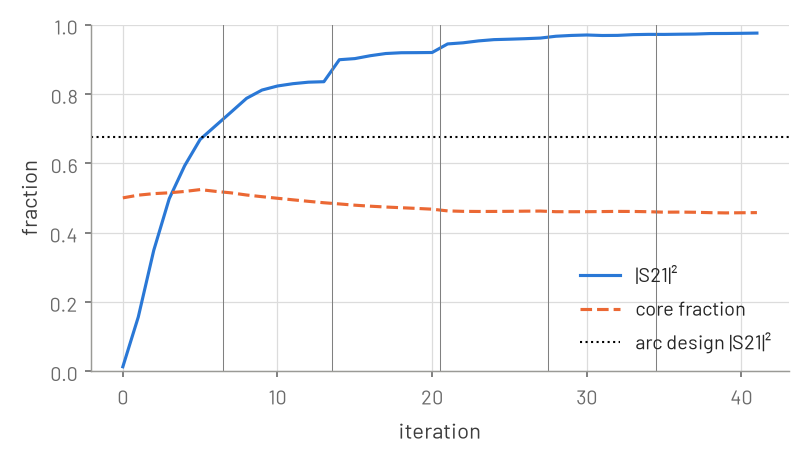

In [8]:
transmission, fraction = np.array(history).T
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(transmission, label="|S21|²")
ax.plot(fraction, label="core fraction")
ax.axhline(t_arc, color="k", ls=":", lw=1, label="arc design |S21|²")
for k in range(STEPS_PER_BETA, n_steps, STEPS_PER_BETA):
    ax.axvline(k - 0.5, color="gray", lw=0.5)
ax.set_ylim(0, 1)
ax.set_xlabel("iteration")
ax.set_ylabel("fraction")
ax.legend(loc="lower right");

## The design

The physical density at the four snapshots, white core and black cladding. The
design grows from the uniform start into curved strips of core about the inner
corner; by iteration 41 (β = 32) it is nearly binary.

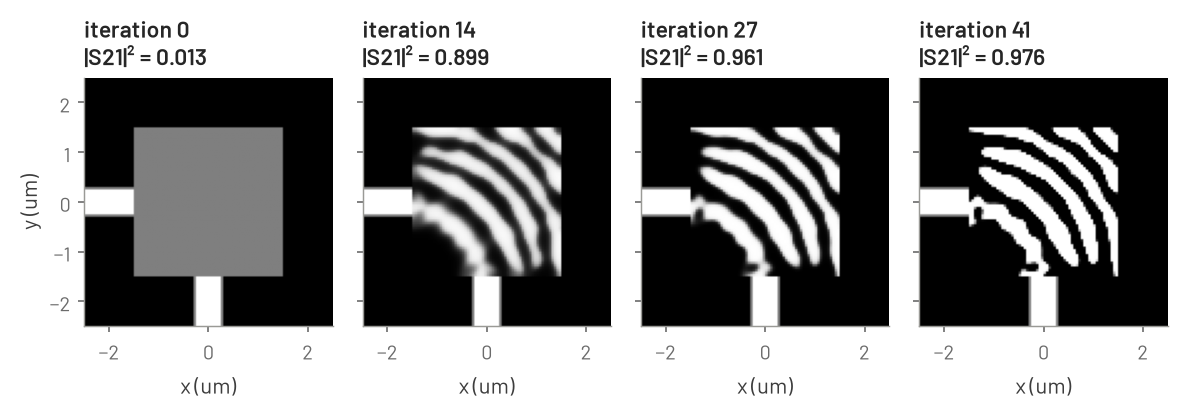

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, k in zip(axes, snapshot_at, strict=True):
    ax.imshow(
        window(snapshots[k]), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1
    )
    ax.set_title(f"iteration {k}\n|S21|² = {history[k][0]:.3f}")
    ax.set_xlabel("x (um)")
axes[0].set_ylabel("y (um)")
fig.tight_layout();

The design we evaluate is `final`: the last physical density thresholded at 0.5, a
two-material image. Every number after this comes from it. Below, |S21|² of
iteration 41 next to that of `final`, and the share of pixels the last density
already had within 0.05 of 0 or 1. The element permittivities of `final` stay
fractional along material edges, since each element samples the pixels bilinearly.

In [10]:
last = physical(rho, BETAS[-1])
final = (last > 0.5).astype(float)
s_final = s_matrix(final)
t_final = abs(complex(s_final["p2", "p1"][0])) ** 2
binary = float(jnp.mean((last < 0.05) | (last > 0.95)))
core = float(final.mean())
print(f"iteration {n_steps - 1}: |S21|^2 = {history[-1][0]:.4f} at beta = {beta:.0f}")
print(f"final: |S21|^2 = {t_final:.4f}, thresholded at 0.5, {core:.1%} core")
print(f"{100 * binary:.1f} % of the pixels lie within 0.05 of 0 or 1")

iteration 41: |S21|^2 = 0.9756 at beta = 32
final: |S21|^2 = 0.9746, thresholded at 0.5, 45.4% core
93.7 % of the pixels lie within 0.05 of 0 or 1
